# Bayesian Networks from Knowledge Graphs

So far our Bayesian networks have been built from tables of probabilities that we were *given*. In practice the probabilities usually have to be *learned*, and the data are often not a neat table of observations but a **knowledge graph**: a collection of entities (genes, diseases, drugs, ...) joined by labelled relations. This section shows how to turn a knowledge graph into a Bayesian network and how to use it to make predictions. The pipeline has six steps, and each one is a decision that you will have to make and justify when you build a network of your own.

1. **Choose the variables.** Decide which entity types become random variables, and what the *states* of each variable are.
2. **Choose the structure.** Decide which relations in the graph tell you about which dependencies, and draw a valid DAG.
3. **Derive training data from the graph.** Turn edges into counts, keeping some edges back for testing.
4. **Estimate the conditional probability tables (CPTs)** from the counts, handling the sparsity that is typical of graphs.
5. **Do inference** without ever building a table that is too big to store.
6. **Check and evaluate** the network, against sanity tests, baselines and the withheld edges.

We use the **HALD** (Human Ageing and Longevity Dataset) knowledge graph, distributed as an RDF file, which we read with Owlready2 and query with SPARQL, as in the earlier sections. It contains genes, diseases, mutations and several kinds of molecule, linked by relations extracted from the literature. The question we shall ask of the finished network is the one a knowledge-graph *link prediction* problem asks: *which genes are most likely to be linked to a given disease, among those not yet known to be linked to it?*

The network is related to the meta-path methods that you have already seen. A meta-path score counts paths of a given type between two nodes and discounts hubs. The Bayesian network instead gives a *probability model* of the same relations, so it can answer many different questions (in either direction), it handles uncertainty about missing values, and its assumptions are written down as a DAG. We return to the connection when we define the CPTs.

In [1]:
import collections
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from owlready2 import World

HALD_FILE = "HALD.rdf"          # the RDF/XML file, in the same folder as this notebook
SEED = 2024                     # seed for the train/withheld split
METAB = ["Lipid", "Carbohydrate"]   # the node classes that we treat as "metabolites"

## Reading the HALD graph with Owlready2

HALD is stored as an OWL/RDF file: each node is an `owl:NamedIndividual` with a class (its type), a few attributes, and one statement for every link to another node, where the *relation* is the property of the statement. We load it with Owlready2, as in the earlier sections. Loading puts the triples into a local quadstore, which we can explore in two ways: through the **Python API**, in which nodes are Python objects and relations are attributes, and through **SPARQL**. The Python API is convenient for looking at one node, but for the bulk extraction that we need to build count matrices, SPARQL is the better tool: the query says *which* pairs we want, and the quadstore does the work.

In [2]:
world = World()                                                   # a fresh quadstore, so that re-running this cell starts clean
onto = world.get_ontology(Path(HALD_FILE).resolve().as_uri()).load()
print(f"{len(list(onto.individuals())):,} individuals, {len(list(onto.object_properties())):,} object properties, "
      f"{len(list(onto.classes()))} classes")

# The Python API: every node is a Python object, and its links are attributes
mlh1 = onto.MLH1
print("MLH1 is a", mlh1.is_a, "; it is linked to", len(mlh1.associated), "entities by 'associated', e.g.", mlh1.associated[:3])

12,256 individuals, 3,058 object properties, 10 classes
MLH1 is a [HALD.Gene] ; it is linked to 6 entities by 'associated', e.g. [HALD.Death, HALD.rs1800734, HALD.rs749072]


We now use SPARQL to summarise the graph. A useful detail: HALD happens to contain a relation named `type`, which is not the same thing as `rdf:type` (the class of a node). SPARQL distinguishes them by their full IRIs (`h:type` and `rdf:type`), so the queries below are not confused by it; a program that matched the *local name* `type` would be.

In [3]:
PREFIXES = "PREFIX h: <http://www.dummy.info/new.owl#>\n"

def sparql(query):
    """Run a SPARQL query against the loaded graph; returns a list of rows."""
    return list(world.sparql(PREFIXES + query))

# How many nodes of each type?
rows = sparql("""SELECT ?class (COUNT(?node) AS ?n) WHERE {
    ?node a owl:NamedIndividual . ?node a ?class . ?class a owl:Class } GROUP BY ?class ORDER BY DESC(?n)""")
display(pd.DataFrame([(c.name, n) for c, n in rows], columns=["node type", "nodes"]).set_index("node type").T)

# How many links does each relation contribute?
rows = sparql("""SELECT ?rel (COUNT(*) AS ?n) WHERE { ?rel a owl:ObjectProperty . ?s ?rel ?o }
                   GROUP BY ?rel ORDER BY DESC(?n)""")
print(f"{len(rows):,} relation names carry {sum(n for _, n in rows):,} links.   The most common:")
display(pd.DataFrame([(r.name, n) for r, n in rows[:8]], columns=["relation", "links"]).set_index("relation").T)

node type,Gene,Disease,Mutation,RNA,Carbohydrate,Lipid,Peptide,Protein,Pharmaceutical_Preparations,Toxin
nodes,5624,3501,2216,388,211,177,82,29,15,13


3,058 relation names carry 116,494 links.   The most common:


relation,associated,include,increase,result,cause,lead,occur,characterized
links,19110,5542,2088,2015,2006,1990,1600,1468


The graph has more than 3,000 distinct relation names, because the relations were extracted automatically from text and are mostly verbs ("associated", "include", "increase", "cause", ...). Many of them are near-synonyms, and most occur only a handful of times, so there are far too few examples of each one to estimate a probability from. We therefore make our first modelling decision: **collapse all relations to a single "linked" relation, and ignore direction**. Two entities are linked if *any* relation joins them, in *either* direction. This throws away information, but it is what makes counting possible, and it is a decision you should always state and justify. (A Bayesian network that kept `associated` and `cause` separate would need many more variables or much more data.)

In SPARQL, "any relation" is a variable in the predicate position (`?a ?rel ?b`), and "either direction" is a `UNION` of the pattern with its mirror image. The function below returns the distinct linked pairs of two node types, and we use it to build the three relations that the network will use, plus one that it will not.

In [4]:
def link_table(types_a, types_b):
    """Distinct pairs (a, b), a of a class in types_a and b of a class in types_b, linked by ANY relation in
    EITHER direction. The UNION makes the query symmetric, which collapses the relation vocabulary to a single
    'linked' relation and ignores direction."""
    values = lambda var, types: f"VALUES {var} {{ " + " ".join("h:" + t for t in types) + " }"
    query = f"""SELECT DISTINCT ?a ?b WHERE {{
        {values('?type_a', types_a)} {values('?type_b', types_b)}
        ?a a ?type_a . ?b a ?type_b .
        {{ ?a ?rel ?b }} UNION {{ ?b ?rel ?a }}
        ?rel a owl:ObjectProperty .
        FILTER (?a != ?b) }}"""
    out = pd.DataFrame([(a.name, b.name) for a, b in sparql(query)], columns=["source", "target"])
    return out.sort_values(["source", "target"]).reset_index(drop=True)

gene_disease = link_table(["Gene"], ["Disease"])
gene_gene = link_table(["Gene"], ["Gene"])                      # symmetric, so both directions are present
disease_metabolite = link_table(["Disease"], METAB)
gene_metabolite = link_table(["Gene"], METAB)                   # NOT used by the model: kept for a later check

print(f"gene-disease: {len(gene_disease):,}   gene-gene (both directions): {len(gene_gene):,}   disease-metabolite: {len(disease_metabolite):,}")

gene-disease: 9,454   gene-gene (both directions): 5,566   disease-metabolite: 2,481


## From relations to variables

Our network has four variables. For each one we have to say what the *states* are, because a random variable in a Bayesian network built from a graph is "which entity?", with one state for every entity of that type.

| Variable | Meaning | States | Relation used to inform it |
|:--|:--|:--|:--|
| $G$ | a gene | every gene in the universe | gene–disease links (training) |
| $N$ | a *neighbour* of $G$: a gene it is linked to | every gene | gene–gene links |
| $Z$ | a disease | every disease in the universe | gene–disease links (training) |
| $L$ | a metabolite (a lipid or carbohydrate) | the $K$ most linked metabolites, plus "other" | disease–metabolite links |

The roles are chosen to mirror a common pattern in knowledge graphs. $G$ is the entity that we shall want to rank. $N$ is a *mediator*: a second entity type that is linked both to $G$ and to $Z$, providing indirect evidence in the same way as the middle node of a meta-path. (Here the mediator happens to be a gene again, as with protein–protein interactions.) $L$ is an *attribute* of the disease, a "descriptive" variable with many states, which we must reduce.

Three points about states deserve comment.

* **Large state spaces.** $G$, $N$ and $Z$ have thousands of states. The software of the previous sections, which stores each CPT as a dense array, would need tables of the sizes shown below.
* **Reducing a state space.** Metabolites have hundreds of possible values, most of which occur on only one or two diseases. A distribution over them cannot be estimated reliably, so we keep the most frequent ones and merge the rest into a single "other" state. There is a trade-off: more states keep more information, but each CPT row is estimated from fewer examples.
* **Why not use a link as a variable?** An alternative design would use a binary variable for each potential link ("is gene $g$ linked to disease $z$?"), but with thousands of genes and diseases that would be millions of variables. Using the entity itself as the state keeps the network small.

### Universe and withheld links

We restrict attention to a *universe* of entities with enough evidence to be useful: genes with at least one disease link, and diseases with at least two gene links (so that a disease can lose a link to the test set and still have evidence left). Then we **withhold a random 20% of the gene–disease links**. Everything from here on (counts, CPTs, baselines) must use the remaining *training* links only, otherwise the test would be meaningless; this is called *leakage*. Because we collapsed the links to be undirected, there is only one copy of each link to remove. The links are sorted before shuffling so that the split depends only on the seed.

In [5]:
# Universe: genes with at least one disease link; diseases linked to at least two genes
# (so that a disease can lose one edge to the withheld set and still have evidence left).
n_links = gene_disease.groupby("target").size()          # genes linked to each disease
diseases = sorted(n_links[n_links >= 2].index)
gene_disease = gene_disease[gene_disease.target.isin(diseases)]
genes = sorted(gene_disease.source.unique())
g_idx = {g: i for i, g in enumerate(genes)}
z_idx = {z: i for i, z in enumerate(diseases)}
nG, nZ = len(genes), len(diseases)

# Withhold a random 20% of the gene-disease links. Sort first, so the split depends only on SEED.
pairs = np.array([(g_idx[g], z_idx[z]) for g, z in zip(gene_disease.source, gene_disease.target)])
pairs = pairs[np.lexsort((pairs[:, 1], pairs[:, 0]))]
perm = np.random.default_rng(SEED).permutation(len(pairs))
n_held = int(0.2 * len(pairs))
held, train = pairs[perm[:n_held]], pairs[perm[n_held:]]
print(f"{nG:,} genes, {nZ:,} diseases;  {len(train):,} training links, {len(held):,} withheld links")

2,324 genes, 699 diseases;  7,228 training links, 1,806 withheld links


### Counting

All of the CPTs will be estimated from three **count matrices**, stored as sparse matrices because almost all of the entries are zero. In keeping with our notation, the first index is the variable named first: `CZG[z, g]` counts links between disease $z$ and gene $g$, and so on. The metabolite variable is reduced here by keeping the most-linked metabolites.

In [6]:
# Count matrices (sparse). Rows are indexed by the first letter(s) of the name, as in the rest of the notes.
CZG = sp.csr_matrix((np.ones(len(train)), (train[:, 1], train[:, 0])), shape=(nZ, nG))   # CZG[z, g] = 1 if training link g-z

gg = [(g_idx[a], g_idx[b]) for a, b in zip(gene_gene.source, gene_gene.target) if a in g_idx and b in g_idx]
NB = sp.csr_matrix((np.ones(len(gg)), tuple(zip(*gg))), shape=(nG, nG))                  # NB[n, g] = 1 if genes n and g are linked
NB.data[:] = 1

# Metabolites (lipids and carbohydrates): keep the K most-linked metabolites (among universe diseases) and merge the rest into 'other'.
dm = disease_metabolite[disease_metabolite.source.isin(diseases)]
K = 20
top_met = dm.target.value_counts().head(K).index.tolist()
metabolites = top_met + ["other"]
l_idx = {l: i for i, l in enumerate(metabolites)}
CLZ = sp.lil_matrix((len(metabolites), nZ))                                                # CLZ[l, z] = 1 if disease z has metabolite m
for z, l in zip(dm.source, dm.target):
    CLZ[l_idx.get(l, K), z_idx[z]] = 1
CLZ = CLZ.tocsr()
nL = len(metabolites)

summary = pd.DataFrame({
    "relation": ["gene-disease (training)", "gene-gene", "disease-metabolite (kept)"],
    "number of links": [CZG.nnz, NB.nnz // 2, CLZ.nnz],
    "used for": ["P(G), P(Z|G,N)", "P(N|G), P(Z|G,N)", "P(L|Z)"]})
display(summary)
print(f"{K} named metabolites cover {dm.target.isin(top_met).sum()} of {len(dm)} disease-metabolite links")

,relation,number of links,used for
0,gene-disease (training),7228,"P(G), P(Z|G,N)"
1,gene-gene,2039,"P(N|G), P(Z|G,N)"
2,disease-metabolite (kept),1313,P(L|Z)


20 named metabolites cover 1017 of 2087 disease-metabolite links


## The structure of the network

We choose the DAG

$$P(G,N,Z,L)=P(G)\,P(N\vert G)\,P(Z\vert G,N)\,P(L\vert Z)$$

with edges $G\to N$, $G\to Z$, $N\to Z$ and $Z\to L$.

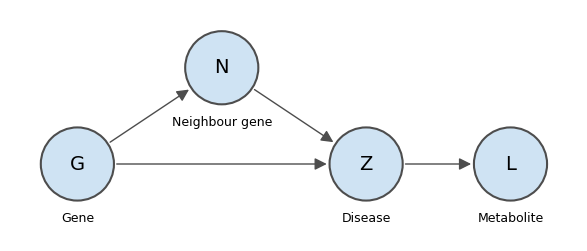

In [7]:
from matplotlib.patches import Circle, FancyArrowPatch

pos = {"G": (0, 1), "N": (1.5, 2), "Z": (3, 1), "L": (4.5, 1)}
names = {"G": "Gene\nG", "N": "Neighbour gene\nN", "Z": "Disease\nZ", "L": "Metabolite\nL"}
dag_edges = [("G", "N"), ("G", "Z"), ("N", "Z"), ("Z", "L")]

fig, ax = plt.subplots(figsize=(8, 3))
r = 0.38
for a, b in dag_edges:
    (x0, y0), (x1, y1) = pos[a], pos[b]
    d = np.hypot(x1 - x0, y1 - y0)
    ax.add_patch(FancyArrowPatch((x0 + (x1 - x0) * r / d, y0 + (y1 - y0) * r / d),
                                 (x1 - (x1 - x0) * r / d, y1 - (y1 - y0) * r / d),
                                 arrowstyle="-|>", mutation_scale=18, color="0.3"))
for k, (x, y) in pos.items():
    ax.add_patch(Circle((x, y), r, facecolor="#cfe3f3", edgecolor="0.3", lw=1.5))
    ax.text(x, y, k, ha="center", va="center", fontsize=14)
    ax.text(x, y - r - 0.12, names[k].split("\n")[0], ha="center", va="top", fontsize=9)
ax.set_xlim(-0.7, 5.2); ax.set_ylim(0.2, 2.6); ax.set_aspect("equal"); ax.axis("off")
plt.show()

The reasoning behind each edge, in the same style as the construction recipe for Bayesian networks:

* $G$ is a **root**: it has no parent, so we give it a prior, $P(G)$. The prior says how likely a gene is to be linked to *something*; in a graph this is its popularity.
* $G\to N$: the neighbours of a gene depend on the gene.
* $G\to Z$ and $N\to Z$: whether a disease is linked to a gene depends on what we know about the gene itself *and* on what its neighbours are linked to. The distribution $P(Z\vert G,N)$ is the heart of the network.
* $Z\to L$: the metabolites linked to a disease depend on the disease. Once we know the disease, the metabolite gives no *further* information about the genes.

We have chosen to *ignore* some relations that the graph does contain. For example, genes are also linked directly to metabolites, but the network has no $G$–$L$ edge. That is deliberate: it is a modelling choice, and, as we shall see, it gives us a relation on which to test the network.

**Conditional independence.** The structure asserts that $L$ is independent of $G$ and $N$ *given* $Z$: knowing the disease, nothing else about the gene or its neighbour changes the probabilities of the metabolites. In the notation of the earlier sections, $P(L\vert Z,G,N)=P(L\vert Z)$, so $Z$ forms the middle of chains $G\to Z\to L$ and $N\to Z\to L$. $G$ and $L$ are *not* independent without knowing $Z$, because information flows along the chain. Finally $G$ and $N$ are dependent by construction (that is the point of the mediator). These statements are not assumptions that we are free to forget: they are claims about the *data* that may be wrong, and the more we cut the graph, the more we claim. We test the first one numerically below.

**Is the direction causal?** No. We have no evidence that "a gene causes its neighbours" or that "a disease causes a metabolite". We pick directions that give a convenient factorisation, with a root that we want to rank and a single mediator. The same joint distribution could be written with other arrows; the arrows only matter once we start to estimate and smooth the CPTs.

### How big are the CPTs, and how much is backed by data?

The table $P(Z\vert G,N)$ has one entry for every combination of gene, neighbour and disease. We compute its size and compare it with the number of *records* that we can derive from the training graph: a record $(g,n,z)$ exists when $g$ has a training link to $z$ and $n$ is linked to $g$.

In [8]:
nN = nG                                                   # N is also a gene, so it has the same states as G
full_joint = nG * nN * nZ * nL
bn_params = (nG - 1) + nG * (nG - 1) + nG * nG * (nZ - 1) + nZ * (nL - 1)
cpt_cells = {"P(G)": nG, "P(N|G)": nG * nN, "P(Z|G,N)": nG * nN * nZ, "P(L|Z)": nZ * nL}
rows = []
for name, cells in cpt_cells.items():
    rows.append((name, f"{cells:,}", f"{cells * 8 / 1e9:.3f} GB"))
display(pd.DataFrame(rows, columns=["table", "cells", "memory as float64"]))
print(f"Full joint P(G,N,Z,L): {full_joint:,} cells  ({full_joint * 8 / 1e12:.1f} TB)")
print(f"Free parameters of the network, if every CPT were stored in full: {bn_params:,}")

# How much of P(Z|G,N) is backed by data? A 'record' (g, n, z) exists when g has a training link to z AND n is linked to g.
d_train = np.asarray(CZG.sum(axis=0)).ravel()            # training links per gene
n_nb = np.asarray(NB.sum(axis=0)).ravel()                # gene-gene links per gene
records = int((d_train * n_nb).sum())
print(f"Records (g, n, z) available to estimate P(Z|G,N): {records:,}  ({records / cpt_cells['P(Z|G,N)']:.1e} of the table)")
print(f"Genes with at least one gene-gene link: {(n_nb > 0).sum():,} of {nG:,}")

,table,cells,memory as float64
0,P(G),"2,324",0.000 GB
1,P(N|G),"5,400,976",0.043 GB
2,"P(Z|G,N)","3,775,282,224",30.202 GB
3,P(L|Z),"14,679",0.000 GB


Full joint P(G,N,Z,L): 79,280,926,704 cells  (0.6 TB)
Free parameters of the network, if every CPT were stored in full: 3,775,296,203
Records (g, n, z) available to estimate P(Z|G,N): 81,842  (2.2e-05 of the table)
Genes with at least one gene-gene link: 1,113 of 2,324


Storing $P(Z\vert G,N)$ as a dense array of 64-bit numbers would need tens of gigabytes, for a table in which fewer than one cell in 40,000 is backed by even a single record. It would not be sensible to build this table. Two things follow. First, we cannot estimate each cell separately; we need a **smoothing** scheme that fills the cells from related, better-observed quantities. Second, we must do inference by *formulas* that exploit the structure, without materialising the table. Both are described next.

## Estimating the CPTs

**$P(G)$ and $P(L\vert Z)$** are estimated by counting with *Laplace smoothing*: add one imaginary example to every state, so that nothing has probability exactly zero.

$$P(G=g)=\frac{d_g+1}{D+\vert G\vert},\qquad P(L=l\vert Z=z)=\frac{c(l,z)+c_0P(l)}{n_z+c_0}$$

where $d_g$ is the number of training links of gene $g$, $D$ is the total number of training links, $c(l,z)$ counts links of disease $z$ to metabolite $l$, and $n_z$ is the number of metabolites of $z$. The second form shrinks each disease's metabolite distribution towards the overall distribution $P(L)$, so a disease with no recorded metabolites is predicted by the marginal.

**$P(N\vert G)$** is uniform over the genes that $g$ is linked to. For a gene with no neighbours there is nothing to count, so we use the overall distribution of neighbours instead.

**$P(Z\vert G,N)$** is where the work is. We have two sources of evidence about a gene–disease link: the gene's own training links, $c(g,z)$, and what the neighbour $n$ is linked to. We combine them by **interpolation** (also called *Jelinek–Mercer smoothing*, after the language-modelling literature):

$$P(Z=z\vert G=g,N=n)=(1-\lambda_g)\,\frac{c(g,z)}{d_g}+\lambda_g\,P(Z=z\vert n),\qquad P(Z=z\vert n)=\frac{c(n,z)+b\,P(z)}{d_n+b}$$

where $\lambda_g=\lambda$ if the gene has training links and $\lambda_g=1$ if it has none (so that a gene whose links have all been withheld relies entirely on its neighbours). This is a *smoothed estimate* and a *modelling choice*, not a theorem. It does have one property that we need: for every $(g,n)$ it is a proper distribution over $z$, so it is a legitimate CPT.

**Marginalising $N$ without building the table.** Because $N$ appears in the formula only through $P(Z\vert n)$, the sum over $n$ can be done *inside* the formula:

$$P(Z=z\vert G=g)=\sum_n P(n\vert g)\,P(z\vert g,n)=(1-\lambda_g)\,\frac{c(g,z)}{d_g}+\lambda_g\sum_n P(n\vert g)\,P(z\vert n)$$

The last sum is a (sparse) matrix product: `PZ_N @ PN_G`. The result, $P(Z\vert G)$, has one number for each gene–disease pair, and nothing larger is ever stored. In an analogous problem with a mediator of a different type, the same idea applies: *the CPT is defined by a formula, and we compute only the marginals we need*.

The sum $\sum_nP(n\vert g)P(z\vert n)$ has a familiar form. It is the number of paths $g\!-\!n\!-\!z$ of the meta-path *gene – gene – disease* from $g$ to $z$, normalised by the degrees along the way. In other words, it is the "random-walk" version of the path-count scores from the section on meta-paths.

In [9]:
def build_model(CZG, NB, CLZ, lam=0.5, b=1.0, c=1.0):
    """Estimate the four CPTs from count matrices. Nothing larger than (diseases x genes) is ever stored.

    CZG[z, g]  training links between disease z and gene g      NB[n, g]  links between genes n and g
    CLZ[l, z]  links between metabolite l and disease z
    lam        weight given to the neighbour genes when a gene already has training links of its own
    b, c       add-b / add-c (Laplace-style) smoothing for P(Z|N) and P(L|Z)
    """
    nZ, nG = CZG.shape
    nL = CLZ.shape[0]
    d = np.asarray(CZG.sum(axis=0)).ravel()                      # training links per gene
    nz = np.asarray(CZG.sum(axis=1)).ravel()                     # training links per disease
    PZ0 = (nz + 1) / (nz.sum() + nZ)                             # P(Z): smoothed marginal

    PG = (d + 1) / (d.sum() + nG)                                # P(G): add-one smoothed share of links

    deg = np.asarray(NB.sum(axis=0)).ravel()                     # P(N|G=g): uniform over the neighbours of g ...
    PN_G = NB @ sp.diags(1 / np.maximum(deg, 1))                 # (sparse, columns sum to 1)
    PN = np.asarray(NB.sum(axis=1)).ravel() + 0.0                # ... and for a gene with no neighbours, the marginal
    PN = PN / PN.sum() if PN.sum() > 0 else np.full(nG, 1 / nG)  #     distribution of neighbours

    # P(Z|N): what a gene n says about diseases, from its own training links, smoothed towards P(Z)
    PZ_N = (CZG.toarray() + b * PZ0[:, None]) / (d[None, :] + b)

    # Mediator part of P(Z|G) = sum_n P(n|g) P(Z|n): a sparse-times-dense product
    via_N = np.asarray((PZ_N @ PN_G))                            # (nZ x nG)
    iso = deg == 0
    via_N[:, iso] = (PZ_N @ PN)[:, None]                         # genes with no neighbours use the marginal

    lam_g = np.where(d > 0, lam, 1.0)                            # a gene with no training links relies on N entirely
    own = CZG.toarray() / np.maximum(d, 1)[None, :]              # empirical P(Z|g) from the gene's own links
    PZ_G = (1 - lam_g) * own + lam_g * via_N                     # P(Z|G): P(Z|G,N) marginalised over N (see text)

    PL_Z = (CLZ.toarray() + c * ((np.asarray(CLZ.sum(axis=1)).ravel() + 1) / (CLZ.sum() + nL))[:, None])
    PL_Z = PL_Z / PL_Z.sum(axis=0, keepdims=True)                # P(L|Z): smoothed towards the marginal P(L)
    return dict(PG=PG, PN_G=PN_G, PN=PN, PZ_N=PZ_N, PZ_G=PZ_G, PL_Z=PL_Z, PZ0=PZ0, d=d, lam_g=lam_g, own=own, deg=deg)

model = build_model(CZG, NB, CLZ)
print("P(G) sums to", model["PG"].sum().round(6),
      "| every column of P(Z|G) sums to 1:", np.allclose(model["PZ_G"].sum(axis=0), 1),
      "| every column of P(L|Z) sums to 1:", np.allclose(model["PL_Z"].sum(axis=0), 1))

P(G) sums to 1.0 | every column of P(Z|G) sums to 1: True | every column of P(L|Z) sums to 1: True


## Inference

We want $P(G\vert Z=z)$. By Bayes' rule,

$$P(G=g\vert Z=z)\propto P(G=g)\,P(Z=z\vert G=g)$$

For this network the inference is **exact**: the sum over the mediator $N$ was done in the previous step, and the variable $L$ is not needed at all, because $L$ is a descendant of $Z$ that we have not observed (summing over an unobserved leaf gives 1). There is nothing to approximate, so MCMC is not needed. Indeed it would be hopeless here: a categorical variable with thousands of states is exactly the stress test at the end of the section on PyMC.

The function `recommend` ranks the genes for a disease, **excluding genes that already have a training link to it** (we want *new* candidates, not facts we already know). For a first illustration we pick a disease that has few training links and at least one withheld link.

In [10]:
def likelihood(model, z):
    """P(Z=z | G=g) for every gene g at once: one row of the (diseases x genes) matrix P(Z|G)."""
    return model["PZ_G"][z]

def posterior_genes(model, z, uniform_prior=False):
    """P(G | Z=z) by Bayes' rule: proportional to P(G) P(z|G). Exact, and uses only the stored pieces."""
    prior = np.full(len(model["PG"]), 1 / len(model["PG"])) if uniform_prior else model["PG"]
    post = prior * likelihood(model, z)
    return post / post.sum()

def diseases_for_gene(model, g):
    """P(Z | G=g): a column of P(Z|G), with no inference needed."""
    return model["PZ_G"][:, g]

# Training-link lookup, used to exclude links that are already known
known = CZG.toarray() > 0
held_by_disease = collections.defaultdict(list)
for g, z in held:
    held_by_disease[z].append(g)

def recommend(z, k=5):
    p = posterior_genes(model, z)
    p = np.where(known[z], -np.inf, p)            # exclude genes already linked to z in the training graph
    top = np.argsort(-p)[:k]
    return pd.DataFrame({"gene": [genes[g] for g in top], "P(G|Z=z)": p[top],
                         "withheld link?": [g in held_by_disease[z] for g in top]})

# Pick an illustrative disease: few training links, at least one withheld link
cands = [z for z in held_by_disease if known[z].sum() <= 3 and len(held_by_disease[z]) >= 1]
z_demo = sorted(cands, key=lambda z: (-len(held_by_disease[z]), diseases[z]))[0]
print(f"Disease: {diseases[z_demo]}   training genes: {[genes[g] for g in np.flatnonzero(known[z_demo])]}")
print(f"Withheld genes: {[genes[g] for g in held_by_disease[z_demo]]}")
display(recommend(z_demo))

Disease: Aging_Premature   training genes: ['ERCC6', 'LMNB1', 'WRN']
Withheld genes: ['INS', 'ZMPSTE24', 'FGF19', 'FMR1', 'ERCC8', 'LMNA']


,gene,P(G|Z=z),withheld link?
0,BDNF,0.025693,False
1,ERCC8,0.024014,True
2,SYT9,0.021544,False
3,TXNIP,0.016768,False
4,TP53,0.015201,False


A ranked list does not say *why* a gene is plausible. Because the network is a sum of explicit terms, we can break a probability down into the evidence that supports it: the gene's own training links, and each neighbour that contributes. This is the same kind of explanation as listing the paths behind a meta-path score.

In [11]:
def explain(z, g, top=4):
    """Break P(Z=z | G=g) into its parts: the gene's own training links, and each neighbour gene n."""
    lam = model["lam_g"][g]
    parts = [("own training links of " + genes[g], (1 - lam) * model["own"][z, g])]
    nbrs = NB[:, [g]].nonzero()[0]
    for n in nbrs:
        parts.append((f"via neighbour {genes[n]}", lam * model["PN_G"][n, g] * model["PZ_N"][z, n]))
    if len(nbrs) == 0:
        parts.append(("via the marginal neighbour distribution", lam * (model["PZ_N"] @ model["PN"])[z]))
    out = pd.DataFrame(parts, columns=["source of evidence", "contribution to P(z|g)"])
    out = out.sort_values("contribution to P(z|g)", ascending=False).head(top)
    print(f"P(Z={diseases[z]} | G={genes[g]}) = {model['PZ_G'][z, g]:.4f}   (baseline P(Z=z) = {model['PZ0'][z]:.4f})")
    return out

g_top = genes.index(recommend(z_demo).gene[0])
display(explain(z_demo, g_top))

P(Z=Aging_Premature | G=BDNF) = 0.0049   (baseline P(Z=z) = 0.0005)


,source of evidence,contribution to P(z|g)
3,via neighbour ERCC6,0.004810
6,via neighbour MAOA,0.000019
8,via neighbour NR1H4,0.000006
12,via neighbour SORL1,0.000006


## Checking the network

We make three checks. They are cheap, and they find different kinds of mistake.

**Check 1: a marginal against counts.** The network defines a marginal distribution of diseases, $P(Z)=\sum_g P(g)P(Z\vert g)$. This is a *prediction of the model* that we can compare with a count taken directly from the graph: the share of the training links that belong to each disease. They need not be identical, because of smoothing and because the network blends the gene's own links with its neighbours' links, but they should agree closely. A large discrepancy would indicate a bug or a very poor model.

correlation between network marginal and link share: 0.9985
P(Z) sums to 1.000000; largest absolute difference 0.0017


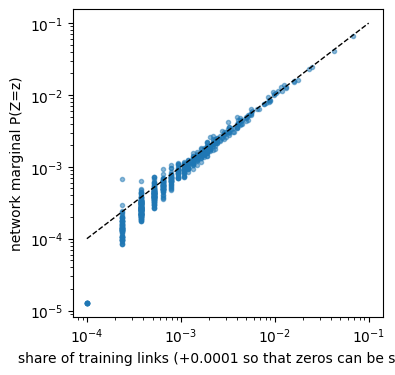

In [12]:
# Sanity test: the network's own marginal P(Z=z) = sum_g P(g) P(z|g), against the share of training links of z
Pz_network = (model["PG"][None, :] * model["PZ_G"]).sum(axis=1)
Pz_counts = np.asarray(CZG.sum(axis=1)).ravel() / CZG.nnz
print(f"correlation between network marginal and link share: {np.corrcoef(Pz_network, Pz_counts)[0, 1]:.4f}")
print(f"P(Z) sums to {Pz_network.sum():.6f}; largest absolute difference {np.abs(Pz_network - Pz_counts).max():.4f}")
fig, ax = plt.subplots(figsize=(4, 4))
ax.loglog(Pz_counts + 1e-4, Pz_network, ".", alpha=0.5)
ax.plot([1e-4, 0.1], [1e-4, 0.1], "k--", lw=1)
ax.set_xlabel("share of training links (+0.0001 so that zeros can be shown)"); ax.set_ylabel("network marginal P(Z=z)")
plt.show()

**Check 2: the sparse calculation against brute force.** The shortcuts that we used, and the independence assumptions that the DAG makes, can be checked on a universe small enough to build the *full joint distribution*, $P(G,N,Z,L)$, as a four-dimensional array and sum it directly. We compare the sparse formula with the enumerated answer, and we test the conditional independence of $G$ and $L$ given $Z$ (this check is a *consequence of the structure*, so it should hold to rounding error; if it did not, we would have implemented a different network from the one that we drew).

In [13]:
# Brute-force check on a small sub-universe: build the full joint P(G,N,Z,L) as a dense 4-D array and
# compare with the sparse calculation. In a universe this small, nothing needs to be avoided.
rng = np.random.default_rng(0)
usable = np.flatnonzero(model["d"] > 0)                               # genes with training links
hub = usable[np.argmax(model["deg"][usable])]                         # start from the gene with most neighbours,
nbrs = [n for n in NB[:, [hub]].nonzero()[0] if model["d"][n] > 0]    # so that the sub-universe contains gene-gene links
extra = [g for g in rng.permutation(usable) if g != hub and g not in nbrs]
gs = np.sort(np.array(([hub] + nbrs + extra)[:12]))
zs = np.sort(np.argsort(-np.asarray(CZG[:, gs].sum(axis=1)).ravel())[:8])   # the 8 diseases with most links to these genes
ms = np.arange(4)
toy = build_model(CZG[zs][:, gs], NB[gs][:, gs], CLZ[ms][:, zs])

def dense_joint(m):
    """P(G,N,Z,L) = P(G) P(N|G) P(Z|G,N) P(L|Z), indexed [g, n, z, l]."""
    nG_, nZ_ = m["PG"].shape[0], m["PZ_N"].shape[0]
    PN_G = m["PN_G"].toarray()
    PN_G[:, m["deg"] == 0] = m["PN"][:, None]                       # isolated genes: marginal neighbour distribution
    PZ_GN = ((1 - m["lam_g"])[None, :, None] * m["own"][:, :, None]    # [z, g, n]
             + m["lam_g"][None, :, None] * m["PZ_N"][:, None, :])
    return np.einsum("g,ng,zgn,lz->gnzl", m["PG"], PN_G, PZ_GN, m["PL_Z"])

J = dense_joint(toy)
print("Full joint sums to", J.sum().round(10), "with shape", J.shape)
PGZ = J.sum(axis=(1, 3))                                            # P(G, Z) by brute-force summation
for z in range(3):
    brute = PGZ[:, z] / PGZ[:, z].sum()                             # P(G | Z=z), by enumeration
    fast = posterior_genes(toy, z)
    print(f"z={z}: max |brute force - sparse| = {np.abs(brute - fast).max():.2e}")

# Conditional independence encoded by the structure: G and L are independent given Z
PGLZ = J.sum(axis=1)                                                # [g, z, l]
PZ_ = PGLZ.sum(axis=(0, 2))
PGL_Z = PGLZ / PZ_[None, :, None]                                   # P(G, L | Z)
PG_Z = PGLZ.sum(axis=2) / PZ_[None, :]                              # P(G | Z)
PL_Zt = PGLZ.sum(axis=0) / PZ_[:, None]                             # [z, l] = P(L | Z)
print(f"max |P(G,L|Z) - P(G|Z) P(L|Z)| = {np.abs(PGL_Z - PG_Z[:, :, None] * PL_Zt[None, :, :]).max():.2e}")

Full joint sums to 1.0 with shape (12, 12, 8, 4)
z=0: max |brute force - sparse| = 2.78e-17
z=1: max |brute force - sparse| = 6.94e-18
z=2: max |brute force - sparse| = 5.55e-17
max |P(G,L|Z) - P(G|Z) P(L|Z)| = 2.08e-17


## Evaluation against the withheld links

The two checks above test the *calculation*. They say nothing about whether the network gives *useful predictions*. For that, we use the 20% of links that we withheld. For every withheld link $(g,z)$ we rank all genes by $P(G\vert Z=z)$, removing those that already have a training link to $z$ (a *filtered* ranking), and record the rank of $g$. We report

* **Hits@$k$**: the fraction of withheld links whose gene is in the top $k$;
* **MRR** (mean reciprocal rank): the average of $1/\text{rank}$, which rewards placing the true gene very high;
* the **median rank**.

A number such as "Hits@10 is 0.14" is meaningless on its own. It is only informative *relative to baselines*, so we compare with:

* **random** ranking;
* **prior only**: ignore the disease and rank by $P(G)$. This asks whether the evidence in the network adds anything to simple popularity. In link prediction on real graphs, hubs are linked to everything, so this baseline is often hard to beat;
* the network with a **uniform prior** (ranking by the likelihood $P(z\vert g)$ alone), which shows the contribution of the evidence on its own.

In [14]:
def rank_metrics(scores, pairs, by="gene", known_mat=None):
    """Rank the withheld link for each (g, z) pair. scores[z, g] is a score for every candidate.
    by='gene': candidates are genes, for the given disease (query: P(G|Z=z)); by='disease': candidates are diseases
    for the given gene. Candidates that already have a TRAINING link to the query are removed (filtered ranking)."""
    kn = known if known_mat is None else known_mat              # which links count as already known
    ranks = []
    for g, z in pairs:
        s = scores[z].copy() if by == "gene" else scores[:, g].copy()
        mask = kn[z].copy() if by == "gene" else kn[:, g].copy()
        target = g if by == "gene" else z
        mask[target] = False
        s[mask] = -np.inf
        ranks.append(1 + np.sum(s > s[target]) + 0.5 * (np.sum(s == s[target]) - 1))   # ties share the rank
    r = np.array(ranks)
    return {"MRR": np.mean(1 / r), "Hits@10": np.mean(r <= 10), "Hits@100": np.mean(r <= 100), "median rank": np.median(r)}

rng = np.random.default_rng(1)
joint_scores = model["PG"][None, :] * model["PZ_G"]                  # P(g) P(z|g), proportional to P(G|Z=z)
prior_only = np.repeat(model["PG"][None, :], nZ, axis=0)
random_scores = rng.random((nZ, nG))
uniform_prior_bn = model["PZ_G"]                                     # BN with a uniform prior: the likelihood alone

res = pd.DataFrame({
    "random": rank_metrics(random_scores, held),
    "prior only P(G)": rank_metrics(prior_only, held),
    "BN, uniform prior": rank_metrics(uniform_prior_bn, held),
    "BN": rank_metrics(joint_scores, held)}).T
display(res.round(3))

,MRR,Hits@10,Hits@100,median rank
random,0.005,0.005,0.044,1078.00
prior only P(G),0.066,0.136,0.382,219.75
"BN, uniform prior",0.030,0.056,0.179,871.50
BN,0.067,0.139,0.378,248.25


**Reading the table.** All of the methods are far better than random, so the graph does contain a great deal of predictable structure. The popularity prior is a strong baseline, and the full network matches it rather than clearly beating it. Ranking by the likelihood alone is much worse than the prior (compare the uniform-prior row), so *the evidence on its own is a poor guide* and what makes the network competitive is combining it with the prior. The smoothing constants ($\lambda=0.5$, $b=1$) were fixed in advance and *not* tuned on these withheld links, since tuning on the test set would make the comparison optimistic; choosing them properly is the subject of one of the exercises. This is an honest and typical outcome, and it shows why the prior-only baseline is essential: without it we might have concluded that a network with Hits@100 of about 0.38 was doing well.

The next table asks *where* the evidence helps, by separating the withheld links into those whose gene has neighbours (so that the mediator contributes) and those whose gene has none.

In [15]:
# Where does the extra evidence help? Split the withheld links by whether the gene has neighbour genes.
has_nb = model["deg"] > 0
for label, keep in (("gene has neighbour genes", [i for i, (g, z) in enumerate(held) if has_nb[g]]),
                    ("gene has no neighbour genes", [i for i, (g, z) in enumerate(held) if not has_nb[g]])):
    sub = held[keep]
    print(label, f"({len(sub)} withheld links)")
    display(pd.DataFrame({"prior only P(G)": rank_metrics(prior_only, sub), "BN": rank_metrics(joint_scores, sub)}).T.round(3))

gene has neighbour genes (1361 withheld links)


,MRR,Hits@10,Hits@100,median rank
prior only P(G),0.087,0.181,0.506,96.0
BN,0.088,0.184,0.497,101.5


gene has no neighbour genes (445 withheld links)


,MRR,Hits@10,Hits@100,median rank
prior only P(G),0.001,0.0,0.004,1569.5
BN,0.002,0.0,0.013,1010.0


For genes with neighbours the network is about level with the prior. Genes with *no* neighbours are mostly genes with few training links of their own as well (some have none at all, because all of their links were withheld), and for them neither method can do anything useful. This is the **cold-start** problem, in which a node has little or no evidence. It is not a flaw that smoothing can repair, and it is worth saying so in any report.

**The effect of the smoothing method.** The network's performance depends on how the sparse CPT is smoothed. Another common estimator, add-$a$ (Dirichlet) smoothing, replaces $\lambda_g$ by a fixed pseudo-count $a$:

$$P(z\vert g)=\frac{c(g,z)+a\sum_n P(n\vert g)P(z\vert n)}{d_g+a}$$

This looks equivalent but it is not, as the next table shows.

In [16]:
# The same network, but with a different way of smoothing P(Z|G): a Dirichlet / add-a estimator
# P(z|g) = (count(g,z) + a * P(z|neighbours)) / (d_g + a), instead of the interpolation used above.
def dirichlet_PZ_G(model, a):
    via_N = (model["PZ_G"] - (1 - model["lam_g"]) * model["own"]) / model["lam_g"]   # recover the neighbour term
    return (CZG.toarray() + a * via_N) / (model["d"][None, :] + a)

rows = {}
for a in (0.1, 1.0, 10.0):
    rows[f"BN, add-a smoothing, a={a}"] = rank_metrics(model["PG"][None, :] * dirichlet_PZ_G(model, a), held)
rows["BN, interpolation (above)"] = rank_metrics(joint_scores, held)
rows["prior only P(G)"] = rank_metrics(prior_only, held)
display(pd.DataFrame(rows).T.round(3))

,MRR,Hits@10,Hits@100,median rank
"BN, add-a smoothing, a=0.1",0.025,0.047,0.083,1329.75
"BN, add-a smoothing, a=1.0",0.030,0.056,0.200,808.50
"BN, add-a smoothing, a=10.0",0.038,0.073,0.301,432.50
"BN, interpolation (above)",0.067,0.139,0.378,248.25
prior only P(G),0.066,0.136,0.382,219.75


The add-$a$ versions are much worse than the prior and than our interpolation. The reason is the factor $d_g$ in the denominator. For a gene $g$ and a disease $z$ that is *not* among its training links, the likelihood is about $a\,/\,(d_g+a)$ times the neighbours' estimate, so it falls as the gene's degree grows. In Bayes' rule this is multiplied by the prior, which *rises* with $d_g$, and the two cancel: the popularity information, which is the best single predictor, is lost. With interpolation the weight $\lambda_g$ does not depend on $d_g$, so the prior's information survives. The general lesson is that smoothing decisions are modelling decisions, and that a baseline tells you when one has gone wrong.

**The same network in the other direction.** One of the advantages of a probabilistic model is that it can answer more than the single query for which it was built. $P(Z\vert G=g)$ is already stored, so ranking *diseases* for a gene needs no inference at all. The comparison baseline is now disease popularity.

In [17]:
# The same network answers the opposite question without any extra work: rank DISEASES for a gene.
disease_popularity = np.repeat(model["PZ0"][:, None], nG, axis=1)
res2 = pd.DataFrame({
    "random": rank_metrics(random_scores, held, by="disease"),
    "disease popularity P(Z)": rank_metrics(disease_popularity, held, by="disease"),
    "BN P(Z|G=g)": rank_metrics(model["PZ_G"], held, by="disease")}).T
display(res2.round(3))

,MRR,Hits@10,Hits@100,median rank
random,0.012,0.017,0.150,329.0
disease popularity P(Z),0.142,0.260,0.664,44.0
BN P(Z|G=g),0.149,0.280,0.682,44.0


The network is slightly better than popularity for ranking diseases, and the difference is again small. The two queries use the same stored distributions, so the evaluation of both is a useful consistency check on the model.

## Using the fourth variable

The variable $L$ has played no part in the recommendations, because we observed the disease, and (as the toy check confirmed) $L$ gives no further information about $G$ once $Z$ is known. It becomes useful when the disease is *unknown*. Suppose we know only that a metabolite $l$ is involved. Then

$$P(G\vert L=l)=\sum_z P(G\vert z)\,P(z\vert l)\propto\sum_z P(l\vert z)\,P(z,G)$$

so the metabolite makes some diseases more probable, and those diseases make some genes more probable. We compute $P(G\vert L=l)$ for each named metabolite. To check the result against something that the network never saw, we use the *direct* gene–metabolite links in the graph, the relation that we chose to leave out of the structure. If the network is capturing something real, genes that are directly linked to a metabolite should rank higher in $P(G\vert L=l)$ than we would expect from popularity alone.

In [18]:
# Evidence about the Metabolite, with the Disease unknown: P(G | L=l) = sum_z P(z | l) P(G | z).
PGZ_joint = model["PZ_G"] * model["PG"][None, :]                      # P(Z=z, G=g), (diseases x genes)
PG_L = PL_Z_rows = model["PL_Z"][:K] @ PGZ_joint                      # row l: P(L=l, G=g), up to a constant
PG_L = PG_L / PG_L.sum(axis=1, keepdims=True)                         # row l: P(G | L=l)

# A check using a relation the network never saw: genes directly linked to the metabolite in the graph
# (gene-metabolite links). Do they rank highly in P(G | L=l), compared with ranking by the prior P(G) alone?
def direct_hits(scores, k=10):
    hits, total = 0, 0
    for l, name in enumerate(top_met):
        direct = [g_idx[g] for g in gene_metabolite.source[gene_metabolite.target == name] if g in g_idx]
        if direct:
            top = set(np.argsort(-scores[l])[:k])
            hits += sum(g in top for g in direct); total += len(direct)
    return hits, total

h, t = direct_hits(PG_L)
h0, _ = direct_hits(np.repeat(model["PG"][None, :], K, axis=0))
print(f"Directly linked genes found in the top 10 of P(G|L=l): {h} of {t}   (prior only: {h0} of {t})")
for l in range(3):
    top = np.argsort(-PG_L[l])[:5]
    print(f"{top_met[l]}: {[genes[g] for g in top]}")

Directly linked genes found in the top 10 of P(G|L=l): 46 of 362   (prior only: 43 of 362)
Glucose: ['INS', 'CRP', 'KL', 'SIRT1', 'MAPT']
Cholesterol: ['INS', 'SIRT1', 'CRP', 'KL', 'MAPT']
Triglycerides: ['INS', 'CRP', 'KL', 'SIRT1', 'APOE']


The network finds only slightly more of the directly linked genes in its top ten than the prior alone does. That is a modest result, and it has an explanation: the network can only reach the metabolite's genes through diseases, and the diseases that carry a metabolite also carry the popular genes. This is useful to know. The relation that we left out of the model *does* contain information that the structure cannot reproduce, and in a real project you would consider adding a $G\to L$ edge, at the price of another large CPT.

## Summary: a checklist for your own network

Every network built from a graph requires the same decisions. When you build one, state each of them, justify it, and say how you tested it.

| Question | What to decide and report |
|:--|:--|
| Which **variables**, and what are their **states**? | Entity types as variables; the universe; any reduction of large state spaces (top-$K$ plus "other"). |
| Which **relations** inform which dependencies? | A table of relation → CPT; relations collapsed or ignored, and why. |
| What is the **structure**? | A valid DAG; the factorisation; the conditional independences it encodes; whether the arrows are causal. |
| What is the **training data**? | Counts derived from *training* edges only; both directions of a withheld edge removed; the seed. |
| How is each **CPT estimated**? | Counting; the smoothing method and its parameters; the proportion of each CPT that is backed by data. |
| How is a **large CPT avoided**? | Marginalise the mediator inside a formula; store only the marginal that is needed. |
| Is the **inference** exact or approximate? | Exact when the structure allows; otherwise sampling (earlier sections). |
| How is it **checked**? | A marginal against counts; a brute-force comparison on a toy universe; the independence assumptions. |
| How is it **evaluated**? | A ranking metric on withheld edges, against random, prior-only and ablated baselines; an honest reading of the table. |
| How is the output **explained**? | Break each probability into the evidence that contributes to it. |

The method is general. Any knowledge graph with a "source" entity that you wish to rank, a "mediator" that provides indirect evidence, a "target" that you condition on and an "attribute" with many values can be handled in this way, and the numbers that we found for HALD (a prior that is hard to beat, a mediator that covers only half of the genes, cold-start entities) are typical of what you will find when you apply it to a larger graph.